In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv(
    "steam-200k.csv",
    header=None
)

df.columns = [
    "user_id",
    "game_title",
    "behavior",
    "value",
    "extra_column"
]

df.head()

,user_id,game_title,behavior,value,extra_column
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (200000, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   user_id       200000 non-null  int64  
 1   game_title    200000 non-null  object 
 2   behavior      200000 non-null  object 
 3   value         200000 non-null  float64
 4   extra_column  200000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB

First 5 Rows:


,user_id,game_title,behavior,value,extra_column
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0



Statistical Summary:


,user_id,game_title,behavior,value,extra_column
count,2.000000e+05,200000,200000,200000.000000,200000.0
unique,NaN,5155,2,NaN,NaN
top,NaN,Dota 2,purchase,NaN,NaN
freq,NaN,9682,129511,NaN,NaN
mean,1.036559e+08,NaN,NaN,17.874384,0.0
std,7.208074e+07,NaN,NaN,138.056952,0.0
min,5.250000e+03,NaN,NaN,0.100000,0.0
25%,4.738420e+07,NaN,NaN,1.000000,0.0
50%,8.691201e+07,NaN,NaN,1.000000,0.0
75%,1.542309e+08,NaN,NaN,1.300000,0.0



Missing Values:
user_id         0
game_title      0
behavior        0
value           0
extra_column    0
dtype: int64

Duplicate Rows:
707


In [4]:
# Remove unnecessary column
df = df.drop(columns=["extra_column"])

# Remove duplicate records
df = df.drop_duplicates().copy()

# Separate purchase and gameplay records
purchase_df = df[df["behavior"] == "purchase"].copy()
play_df = df[df["behavior"] == "play"].copy()

print("Cleaned Dataset:", df.shape)
print("Purchase Records:", purchase_df.shape)
print("Gameplay Records:", play_df.shape)

print("\nBehavior Distribution:")
print(df["behavior"].value_counts())

Cleaned Dataset: (199293, 4)
Purchase Records: (128804, 4)
Gameplay Records: (70489, 4)

Behavior Distribution:
behavior
purchase    128804
play         70489
Name: count, dtype: int64


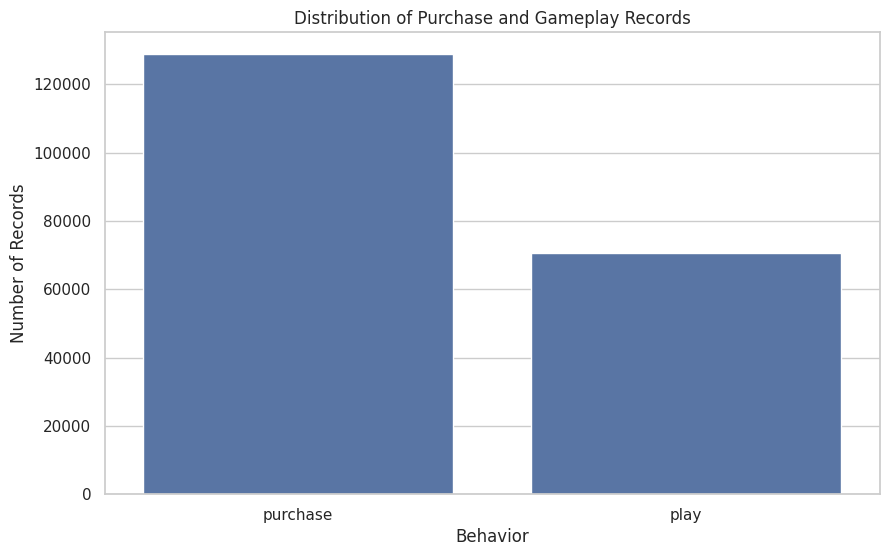

In [5]:
sns.countplot(data=df, x="behavior")

plt.title("Distribution of Purchase and Gameplay Records")
plt.xlabel("Behavior")
plt.ylabel("Number of Records")
plt.show()

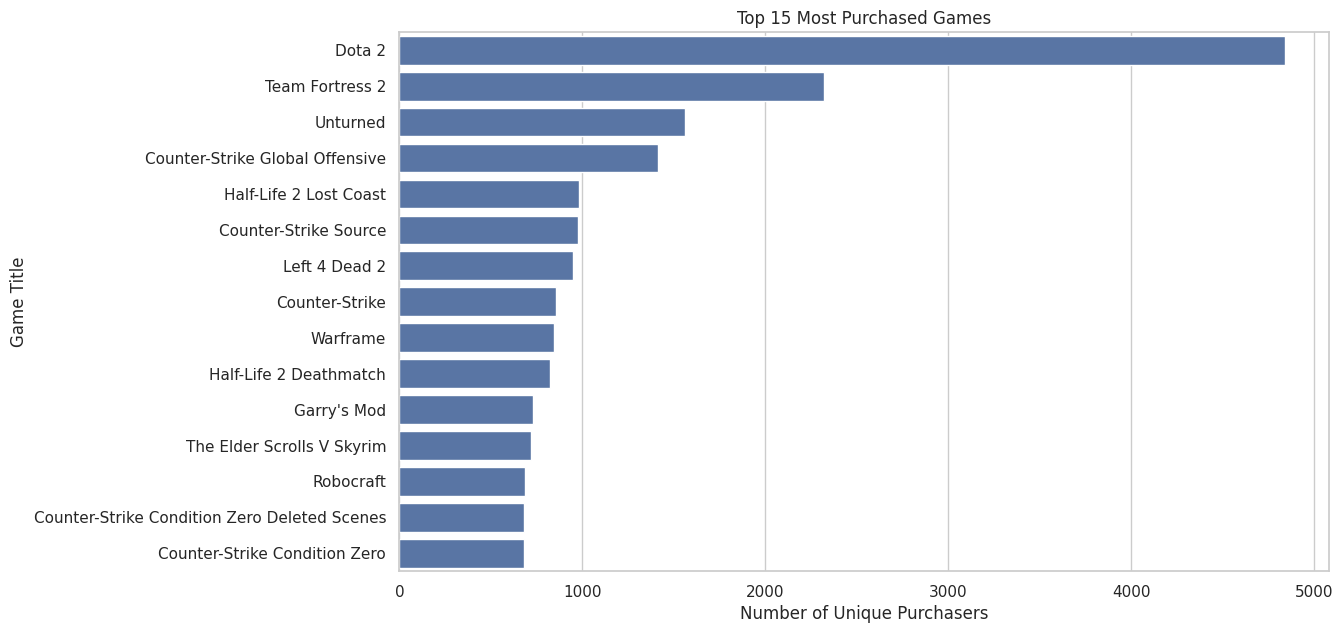

In [6]:
top_games = (
    purchase_df.groupby("game_title")["user_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_games.values,
    y=top_games.index
)

plt.title("Top 15 Most Purchased Games")
plt.xlabel("Number of Unique Purchasers")
plt.ylabel("Game Title")
plt.show()

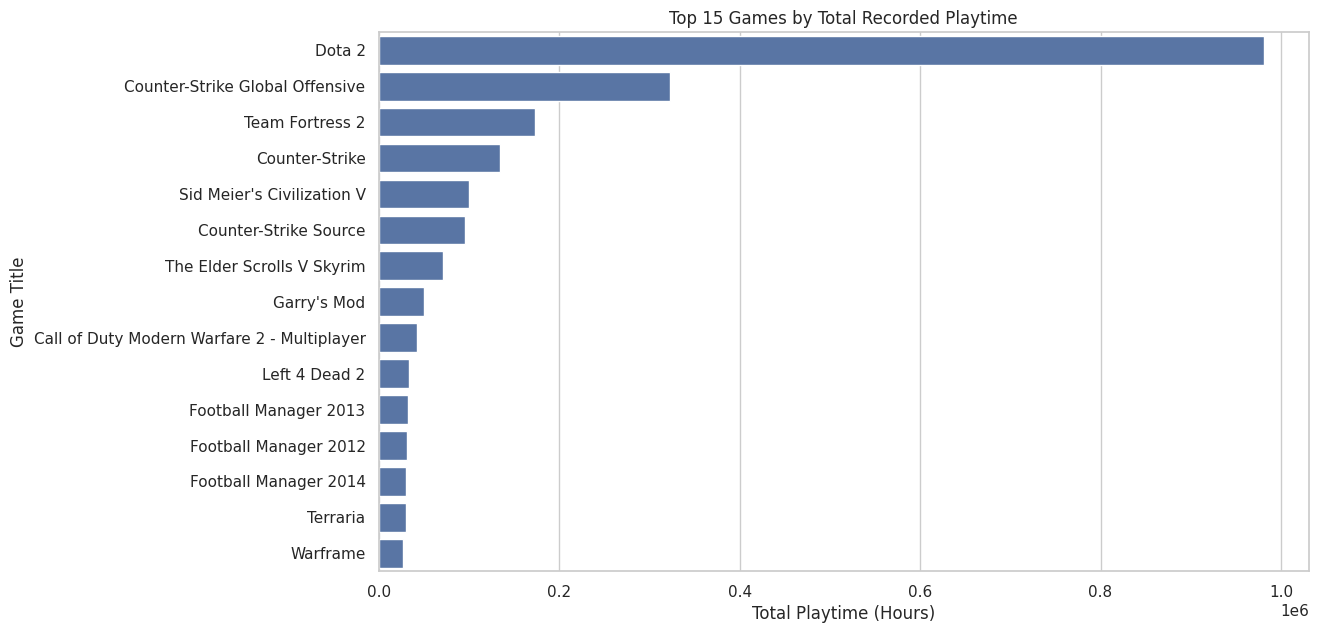

In [7]:
top_played_games = (
    play_df.groupby("game_title")["value"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_played_games.values,
    y=top_played_games.index
)

plt.title("Top 15 Games by Total Recorded Playtime")
plt.xlabel("Total Playtime (Hours)")
plt.ylabel("Game Title")
plt.show()

In [8]:
player_features = df.groupby("user_id").agg(
    total_interactions=("game_title", "count"),
    unique_games=("game_title", "nunique")
)

player_features["total_hours"] = (
    play_df.groupby("user_id")["value"].sum()
)

player_features["total_purchases"] = (
    purchase_df.groupby("user_id")["game_title"].nunique()
)

player_features = player_features.fillna(0)

player_features.head()

,total_interactions,unique_games,total_hours,total_purchases
user_id,,,,
5250,27,21,225.5,21
76767,56,36,1227.0,36
86540,97,82,255.0,82
103360,10,10,0.0,10
144736,9,8,0.1,8


In [9]:
print("Total Players:", len(player_features))

display(player_features.describe())

print("\nMissing Values:")
print(player_features.isnull().sum())

Total Players: 12393


,total_interactions,unique_games,total_hours,total_purchases
count,12393.000000,12393.000000,12393.000000,12393.000000
mean,16.081094,10.393287,278.009021,10.393287
std,51.653103,35.635890,760.270618,35.635890
min,1.000000,1.000000,0.000000,1.000000
25%,2.000000,1.000000,1.300000,1.000000
50%,3.000000,2.000000,13.500000,2.000000
75%,9.000000,6.000000,155.600000,6.000000
max,1566.000000,1068.000000,11754.000000,1068.000000



Missing Values:
total_interactions    0
unique_games          0
total_hours           0
total_purchases       0
dtype: int64


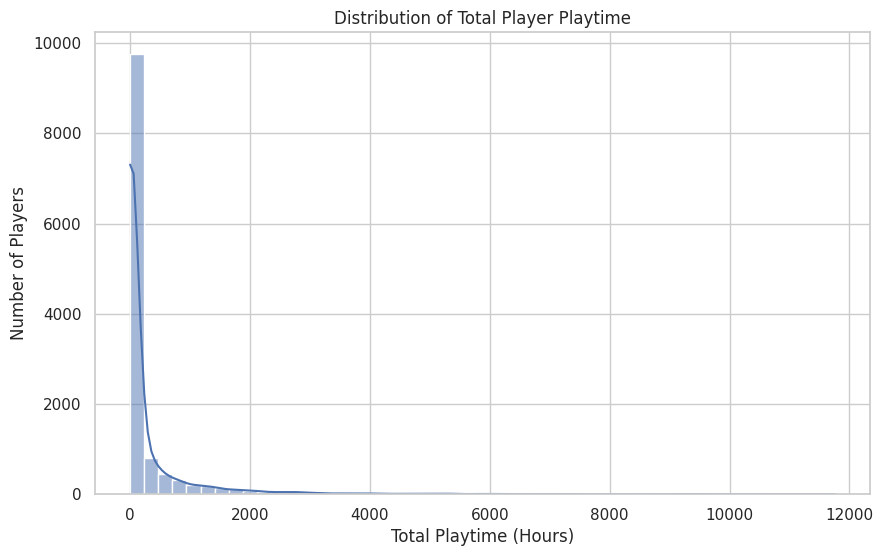

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(
    player_features["total_hours"],
    bins=50,
    kde=True
)

plt.title("Distribution of Total Player Playtime")
plt.xlabel("Total Playtime (Hours)")
plt.ylabel("Number of Players")
plt.show()

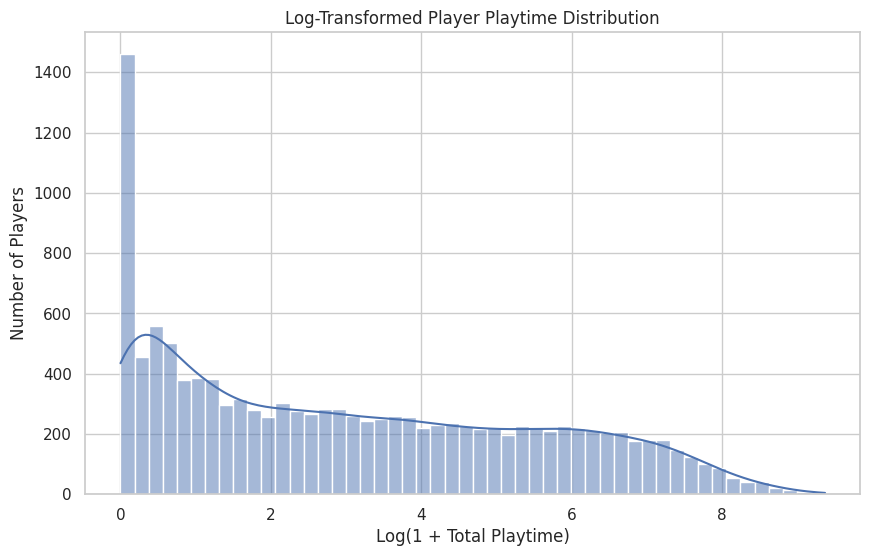

In [11]:
player_features["log_total_hours"] = np.log1p(
    player_features["total_hours"]
)

plt.figure(figsize=(10, 6))

sns.histplot(
    player_features["log_total_hours"],
    bins=50,
    kde=True
)

plt.title("Log-Transformed Player Playtime Distribution")
plt.xlabel("Log(1 + Total Playtime)")
plt.ylabel("Number of Players")
plt.show()

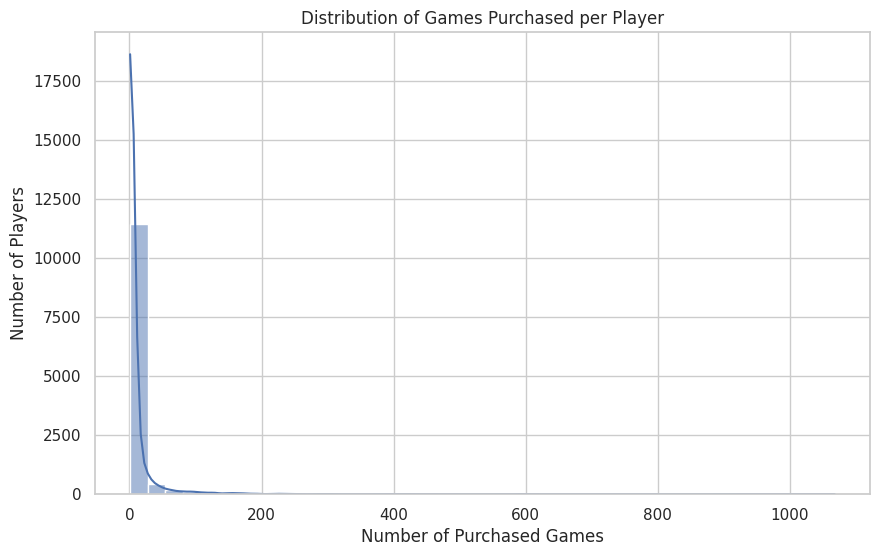

In [12]:
plt.figure(figsize=(10, 6))

sns.histplot(
    player_features["total_purchases"],
    bins=40,
    kde=True
)

plt.title("Distribution of Games Purchased per Player")
plt.xlabel("Number of Purchased Games")
plt.ylabel("Number of Players")
plt.show()

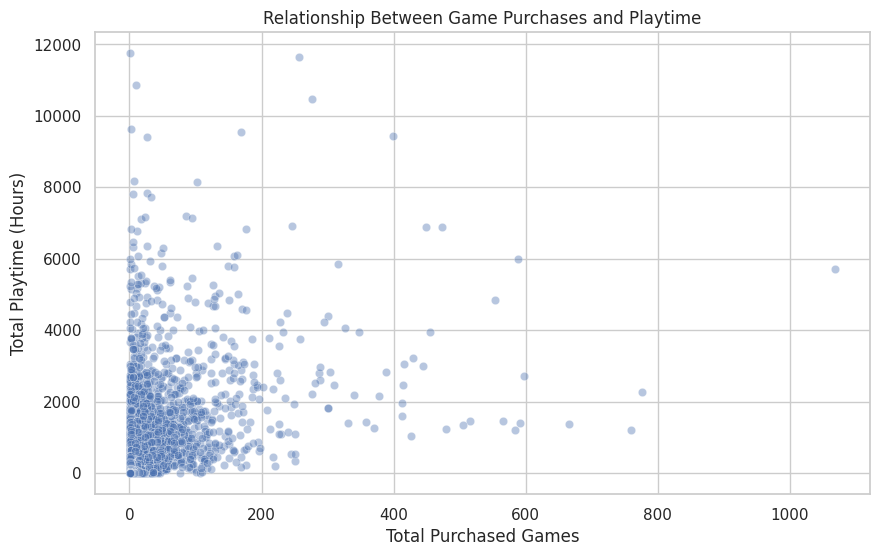

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=player_features,
    x="total_purchases",
    y="total_hours",
    alpha=0.4
)

plt.title("Relationship Between Game Purchases and Playtime")
plt.xlabel("Total Purchased Games")
plt.ylabel("Total Playtime (Hours)")
plt.show()

In [14]:
pearson_corr = player_features[
    ["total_purchases", "total_hours"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = player_features[
    ["total_purchases", "total_hours"]
].corr(method="spearman").iloc[0, 1]

print("Pearson Correlation:", pearson_corr)
print("Spearman Correlation:", spearman_corr)

Pearson Correlation: 0.4664617975702251
Spearman Correlation: 0.5481846705338749


In [15]:
Q1 = player_features["total_hours"].quantile(0.25)
Q3 = player_features["total_hours"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = player_features[
    (player_features["total_hours"] < lower_bound) |
    (player_features["total_hours"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))
print("Percentage of Players:", len(outliers) / len(player_features) * 100)

Lower Bound: -230.14999999999998
Upper Bound: 387.04999999999995
Number of Outliers: 2072
Percentage of Players: 16.719115629791013


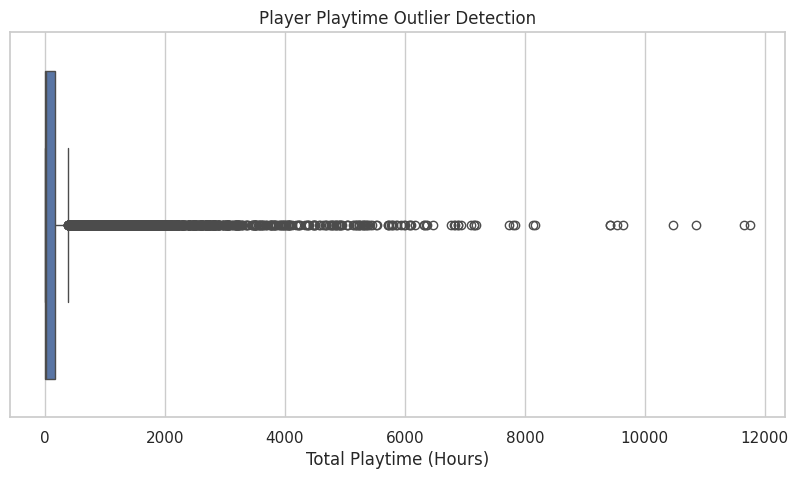

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=player_features["total_hours"]
)

plt.title("Player Playtime Outlier Detection")
plt.xlabel("Total Playtime (Hours)")
plt.show()

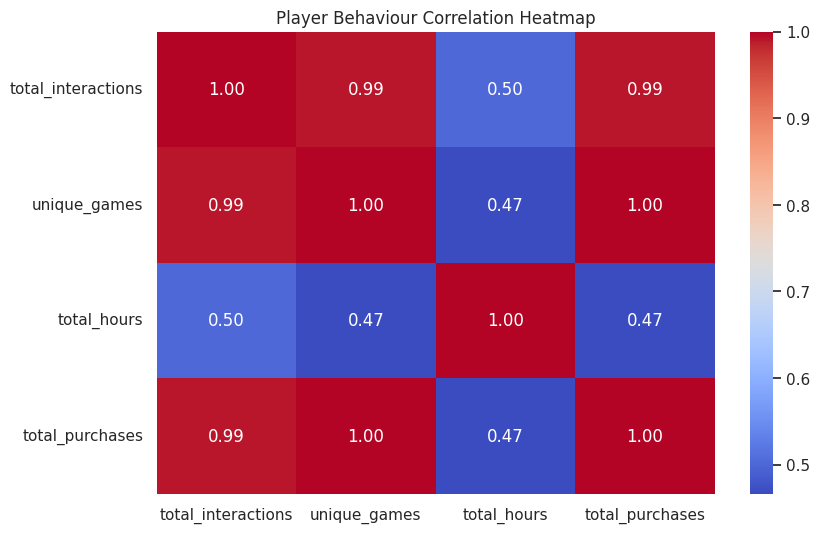

In [17]:
correlation_matrix = player_features[
    [
        "total_interactions",
        "unique_games",
        "total_hours",
        "total_purchases"
    ]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Player Behaviour Correlation Heatmap")
plt.show()

In [18]:
X = player_features[
    ["total_hours", "total_purchases"]
].copy()

X = np.log1p(X)

In [19]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")

Feature scaling completed!


In [20]:
inertia_values = []
silhouette_values = []

K = range(2, 8)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

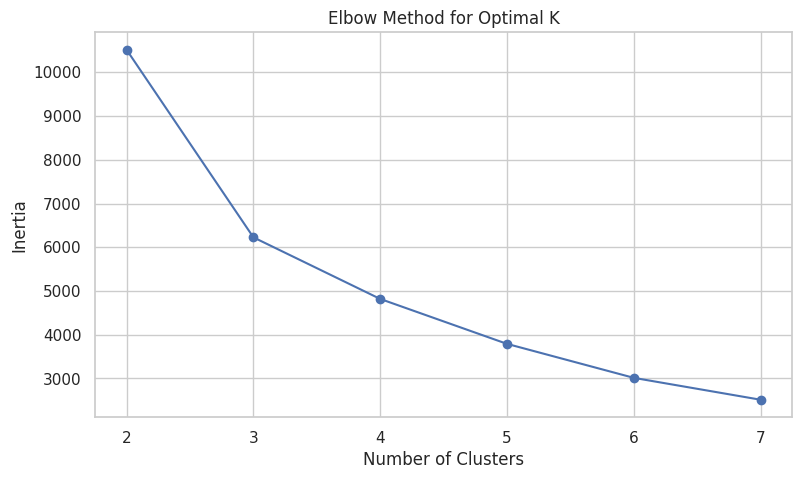

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(K),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(K))
plt.show()

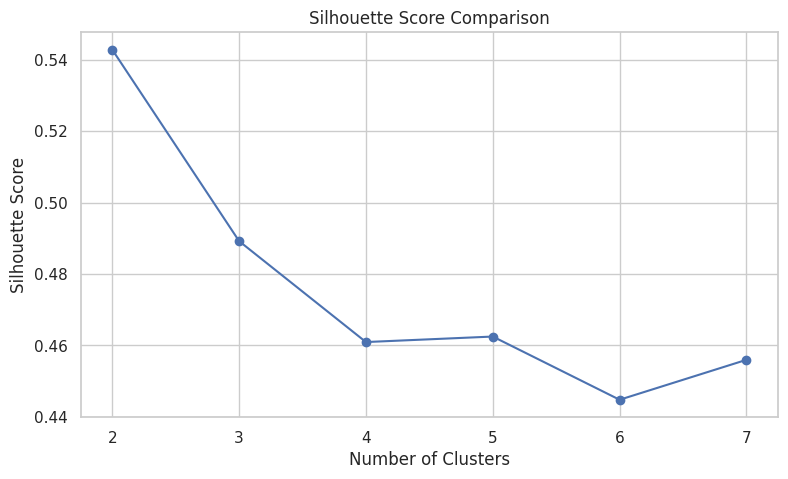

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(K),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(K))
plt.show()

In [23]:
for k, score in zip(K, silhouette_values):
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.5428
K = 3, Silhouette Score = 0.4892
K = 4, Silhouette Score = 0.4609
K = 5, Silhouette Score = 0.4625
K = 6, Silhouette Score = 0.4448
K = 7, Silhouette Score = 0.4560


In [24]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

player_features["cluster"] = kmeans.fit_predict(X_scaled)

print("Player segmentation completed!")

print(
    player_features["cluster"].value_counts().sort_index()
)

Player segmentation completed!
cluster
0    6578
1    3945
2    1870
Name: count, dtype: int64


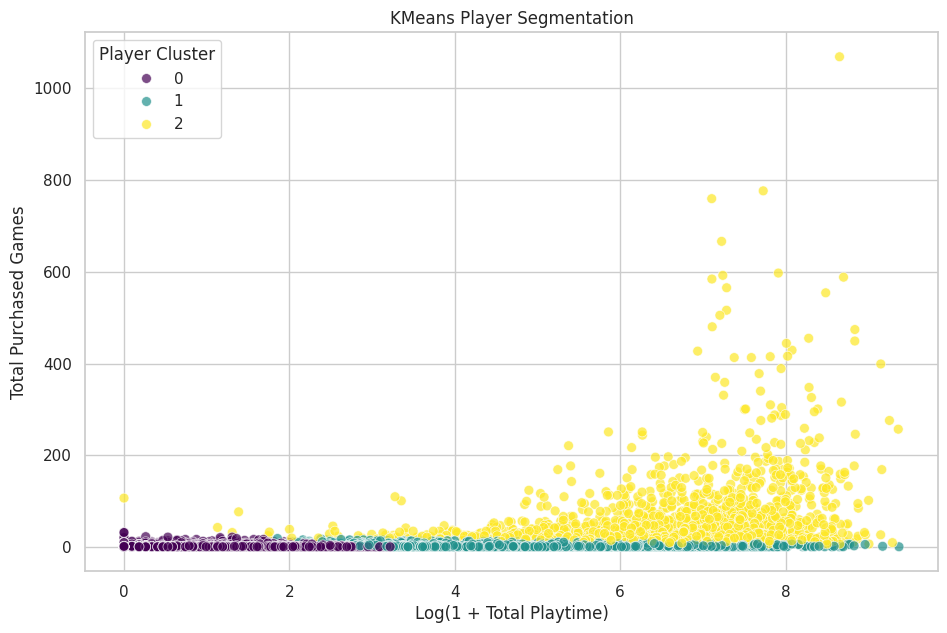

In [25]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=player_features,
    x="log_total_hours",
    y="total_purchases",
    hue="cluster",
    palette="viridis",
    alpha=0.7,
    s=50
)

plt.title("KMeans Player Segmentation")
plt.xlabel("Log(1 + Total Playtime)")
plt.ylabel("Total Purchased Games")
plt.legend(title="Player Cluster")
plt.show()

In [26]:
cluster_summary = player_features.groupby("cluster").agg(
    player_count=("total_hours", "count"),

    avg_hours=("total_hours", "mean"),
    median_hours=("total_hours", "median"),

    avg_purchases=("total_purchases", "mean"),
    median_purchases=("total_purchases", "median")
)

cluster_summary["player_percentage"] = (
    cluster_summary["player_count"] /
    len(player_features) * 100
)

display(cluster_summary.round(2))

,player_count,avg_hours,median_hours,avg_purchases,median_purchases,player_percentage
cluster,,,,,,
0,6578,3.75,1.5,1.91,1.0,53.08
1,3945,296.54,92.0,3.92,3.0,31.83
2,1870,1203.67,721.1,53.90,27.0,15.09


In [27]:
player_features.to_csv(
    "player_features_with_clusters.csv",
    index=True
)

df.to_csv(
    "cleaned_steam_data.csv",
    index=False
)

print("Files exported successfully!")

Files exported successfully!


In [28]:
from google.colab import files

files.download("player_features_with_clusters.csv")
files.download("cleaned_steam_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>